# Lab 11: Attention


## Setup

Run this cell first. It installs the libraries used in this lab.

In [1]:
# Install the libraries used in this lab (safe to re-run)
import sys
!{sys.executable} -m pip install -q torch tensorflow matplotlib pandas

print("Setup complete.")

Setup complete.


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
import os, glob

# Look for the dataset in the same folder as this notebook
candidates = ["Lab_11_QnA_Dataset.csv", "Lab_11_QnA_Dataset_Download.csv"]
csv_path = next((p for p in candidates if os.path.exists(p)), None)

if csv_path is None:
    matches = glob.glob("*QnA*.csv")
    csv_path = matches[0] if matches else None

if csv_path is None:
    raise FileNotFoundError(
        "The dataset was not found. Place Lab_11_QnA_Dataset.csv in the same "
        "folder as this notebook and run the cell again.")

df = pd.read_csv(csv_path)

print("File:", csv_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

File: Lab_11_QnA_Dataset.csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

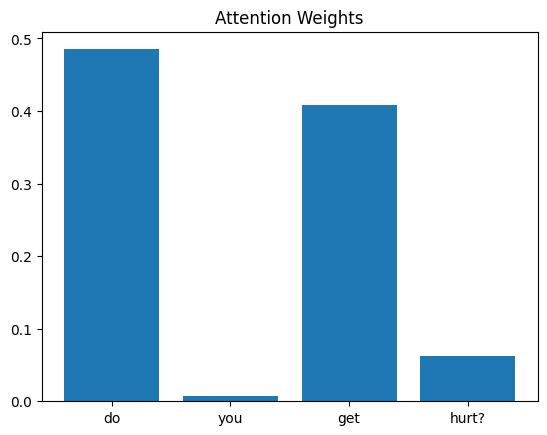

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question          : "do you get hurt?"
Highest attention : "do"  (0.4851)
All the weights   : do=0.4851, you=0.0077, get=0.4080, hurt?=0.0626
Predicted answer  : I don't have a body.
---------------------------------------------------------------------------
Question          : "how old are you?"
Highest attention : "are"  (0.6702)
All the weights   : how=0.0068, old=0.0245, are=0.6702, you?=0.0518
Predicted answer  : People created me.
---------------------------------------------------------------------------
Question          : "who created you?"
Highest attention : "who"  (0.5922)
All the weights   : who=0.5922, created=0.1118, you?=0.0459
Predicted answer  : People created me.
---------------------------------------------------------------------------


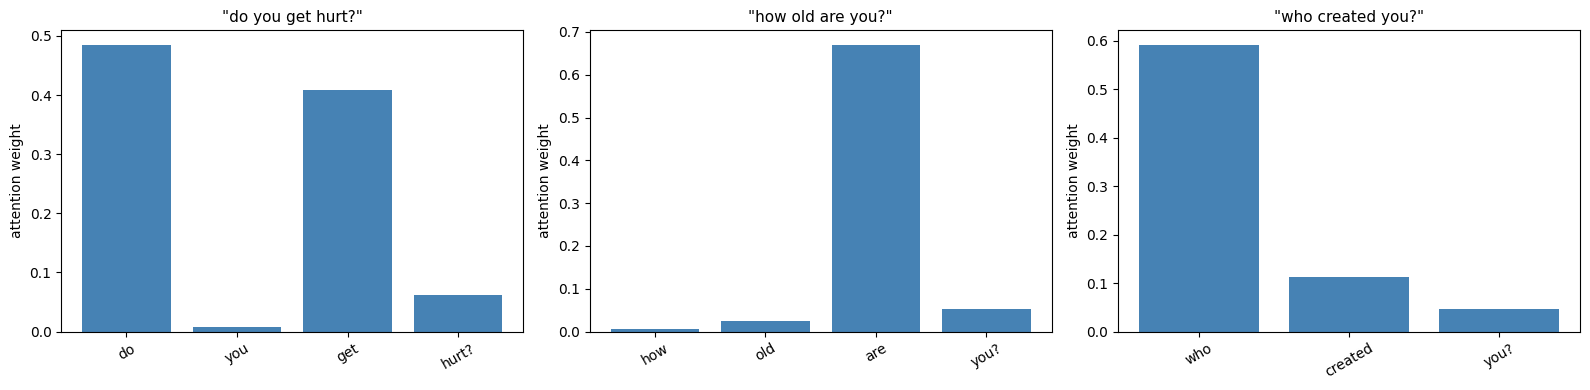

In [8]:
# Task 1: visualize the attention weights for three different questions
import matplotlib.pyplot as plt


def find_question(text):
    """Return the row index of a question in the dataframe."""
    matches = df.index[df["question"] == text.lower()]
    if len(matches) == 0:
        raise ValueError(f"The question '{text}' is not in the dataset.")
    return int(matches[0])


def attention_of(index):
    """Return the words of a question and the attention weight of each word."""
    question = df["question"][index]
    words = question.split()
    with torch.no_grad():
        prediction, weights = model(X[index:index + 1])
    return question, words, weights[0, :len(words)].tolist(), prediction


# Three questions taken from three different answer groups
chosen = ["Do you get hurt?", "How old are you?", "Who created you?"]
indices = [find_question(q) for q in chosen]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, index in zip(axes, indices):
    question, words, weights, prediction = attention_of(index)

    ax.bar(words, weights, color="steelblue")
    ax.set_title(f'"{question}"', fontsize=11)
    ax.set_ylabel("attention weight")
    ax.tick_params(axis="x", rotation=30)

    # The word that received the highest attention weight
    top_word = words[max(range(len(weights)), key=lambda i: weights[i])]
    predicted_id = int(prediction.argmax())
    predicted_answer = df["answer"][df["answer_id"] == predicted_id].iloc[0]

    print(f'Question          : "{question}"')
    print(f'Highest attention : "{top_word}"  ({max(weights):.4f})')
    print(f'All the weights   : ' +
          ", ".join(f"{w}={v:.4f}" for w, v in zip(words, weights)))
    print(f'Predicted answer  : {predicted_answer}')
    print("-" * 75)

plt.tight_layout()
plt.show()

### Answer

| Question | Highest attention | Weight | Predicted answer | Correct? |
|---|---|---|---|---|
| do you get hurt? | **do** | 0.4851 | I don't have a body. | yes |
| how old are you? | **are** | 0.6702 | People created me. | no |
| who created you? | **who** | 0.5922 | People created me. | yes |

**Do the words with the highest attention weights appear important?** Only in one case out of
three.

* In *"who created you?"* the top word **who** is genuinely informative: it is the question word
  that signals the question is about who made the system, and the prediction was correct.
* In *"do you get hurt?"* the top word is **do**, an auxiliary that carries no meaning at all. The
  informative word *hurt* received only 0.0626, while *get* received 0.4080. The answer still came
  out right, but for the wrong reason.
* In *"how old are you?"* the top word is **are**, a copula with no meaning, while *old* &mdash; the
  single most informative word in the sentence &mdash; received only 0.0245. The prediction was
  wrong.

So the attention concentrates mostly on frequent **function words** rather than on content words.
Four things in the code explain this, and together they are the real observation of the task:

1. **The attention layer is not forced to be semantic.** It is a single `Linear(32, 1)` that scores
   each hidden state. Nothing in the loss asks it to prefer meaningful words &mdash; it learns
   whatever reduces the training loss, and frequent words appear in almost every question, so a
   high weight on them is a safe strategy.

2. **The words are not read in context.** `nn.RNN(16, 32)` was created without
   `batch_first=True`, so PyTorch reads the input as `(sequence, batch, features)` while the data is
   `(batch, sequence, features)`. When a single question is passed, every word position becomes its
   own batch item with a sequence length of one, so the hidden state of each word depends on that
   word's embedding alone. The weight therefore reflects **which word it is**, not what role it
   plays in the sentence.

3. **The padding is not masked.** The softmax runs over all eleven padded positions, not only over
   the real words, so part of the attention is spent on padding. In *"who created you?"* the three
   real words together received only 0.7499; the remaining 0.2501 went to padding tokens.

4. **The training loop is incomplete.** The loop in Step 5 calls `loss.backward()` and
   `optimizer.step()` but never `optimizer.zero_grad()`, so the gradients accumulate across all
   fifty epochs instead of being computed fresh each time. The updates are therefore not correct
   gradient steps, and the loss is never printed, so there is no evidence of convergence.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Answer group of the first question : 1
Answer group of the second question: 1
The answer both of them share      : Age doesn't really apply to me.

Question          : "how old are you?"
Highest attention : "are"  (0.6702)
All the weights   : how=0.0068, old=0.0245, are=0.6702, you?=0.0518
Predicted answer  : People created me.
---------------------------------------------------------------------------
Question          : "what's your age?"
Highest attention : "age?"  (0.8344)
All the weights   : what's=0.1093, your=0.0054, age?=0.8344
Predicted answer  : Not at all.
---------------------------------------------------------------------------


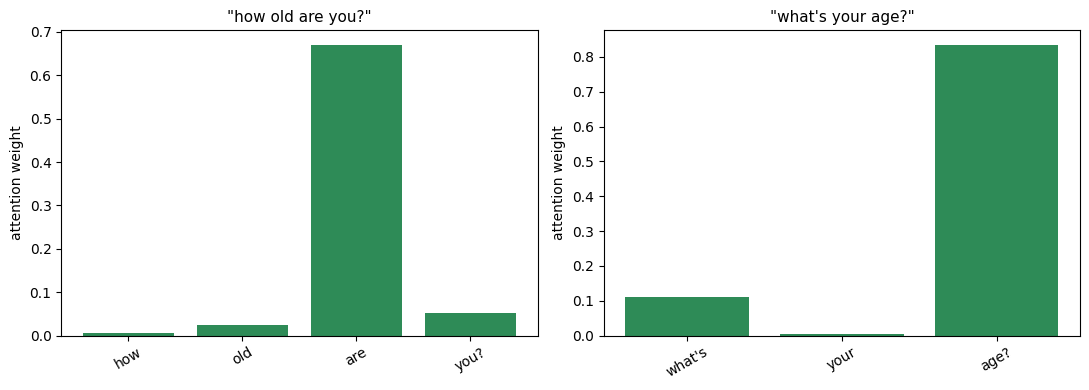

In [9]:
# Task 2: compare the attention of two questions that mean the same thing
pair = ["How old are you?", "What's your age?"]
pair_indices = [find_question(q) for q in pair]

print("Answer group of the first question :", df["answer_id"][pair_indices[0]])
print("Answer group of the second question:", df["answer_id"][pair_indices[1]])
print("The answer both of them share      :", df["answer"][pair_indices[0]])
print()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, index in zip(axes, pair_indices):
    question, words, weights, prediction = attention_of(index)

    ax.bar(words, weights, color="seagreen")
    ax.set_title(f'"{question}"', fontsize=11)
    ax.set_ylabel("attention weight")
    ax.tick_params(axis="x", rotation=30)

    top_word = words[max(range(len(weights)), key=lambda i: weights[i])]
    predicted_id = int(prediction.argmax())
    predicted_answer = df["answer"][df["answer_id"] == predicted_id].iloc[0]

    print(f'Question          : "{question}"')
    print(f'Highest attention : "{top_word}"  ({max(weights):.4f})')
    print(f'All the weights   : ' +
          ", ".join(f"{w}={v:.4f}" for w, v in zip(words, weights)))
    print(f'Predicted answer  : {predicted_answer}')
    print("-" * 75)

plt.tight_layout()
plt.show()

### Answer

Both questions belong to answer group **1**, whose answer is *"Age doesn't really apply to me."*

| Question | Highest attention | Weight | Predicted answer | Correct? |
|---|---|---|---|---|
| how old are you? | **are** | 0.6702 | People created me. | no |
| what's your age? | **age?** | 0.8344 | Not at all. | no |

**Does the model focus on similar or different words?** On completely **different** words. One
question is dominated by the function word *are* and the other by the content word *age*, and the
two predictions are not only both wrong but wrong in two different directions &mdash; one output
belongs to the "who created you" group and the other to the "are you dangerous" group.

**What does this suggest about how attention works?** Attention in this model is a
**per-token scoring mechanism, not a meaning-matching one**. Each position receives a score
computed from its own hidden state, so two sentences that share a meaning but share almost no
vocabulary (*old* versus *age*, *how* versus *what's*) end up with unrelated weight patterns. The
attention weights tell us **where the model looked**, which is not the same as telling us that the
model understood the sentence &mdash; and this case shows the difference clearly, because it looked
somewhere definite in each question and still produced the wrong answer both times.

For attention to behave the way the lecture describes, four things would have to change: the RNN
would need `batch_first=True` so the hidden states actually carry context from the earlier words;
the padding positions would have to be masked out of the softmax; the training loop would need
`optimizer.zero_grad()`; and the dataset would need far more than 168 questions. In practice,
systems that match meaning rather than surface wording rely on pretrained contextual embeddings or
a transformer, where *age* and *old* are placed close together in the vector space before attention
is applied at all.